# 03. Проверка двух находок ноутбука 02

1. **Сентябрь 2024 — структурный сдвиг.** С 2024/25 учебного года школьники получили карты OMNY:
   4 бесплатные поездки в день, круглосуточно, в выходные и каникулы. Старый проездной работал только
   в учебные дни с 5:30 до 20:30. Если гипотеза верна, рост с сентября 2024 должен быть сильнее всего
   **поздно вечером / ночью и в выходные** и **вне Манхэттена**.
2. **Всплески из-за закрытий соседних станций.** Часть «событий» может быть пересадкой пассажиров:
   соседнюю станцию на той же линии закрыли на выходные — люди идут на эту. Проверяем, как часто
   всплеск совпадает с закрытием соседа.

In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from dataset import load_dataset

COL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK2, MUTED, GRID = "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.figsize": (11, 4), "figure.dpi": 110, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED, "lines.linewidth": 2,
    "legend.frameon": False,
})
pd.set_option("display.max_rows", 100, "display.max_colwidth", 60)

df = load_dataset(weather=None)[["station_complex_id", "transit_timestamp", "ridership", "is_closed",
                                  "hour", "dow", "is_holiday", "borough"]]
df["station_complex_id"] = df["station_complex_id"].astype(str)
df["date"] = df["transit_timestamp"].dt.normalize()
st = pd.read_parquet("../data/processed/stations.parquet")
name = st.set_index("station_complex_id")["station_complex"]

## 1. Сентябрь 2024: где и когда вырос спрос

Индекс = средние суточные входы в группе / те же в том же месяце 2023 года. Так сезонность убрана,
и ступенька видна как сдвиг линии. Берём только открытые станции, без праздников.

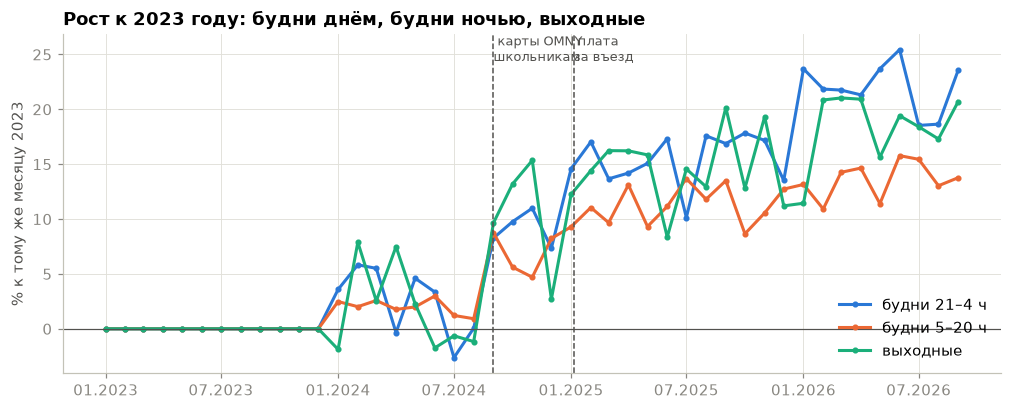

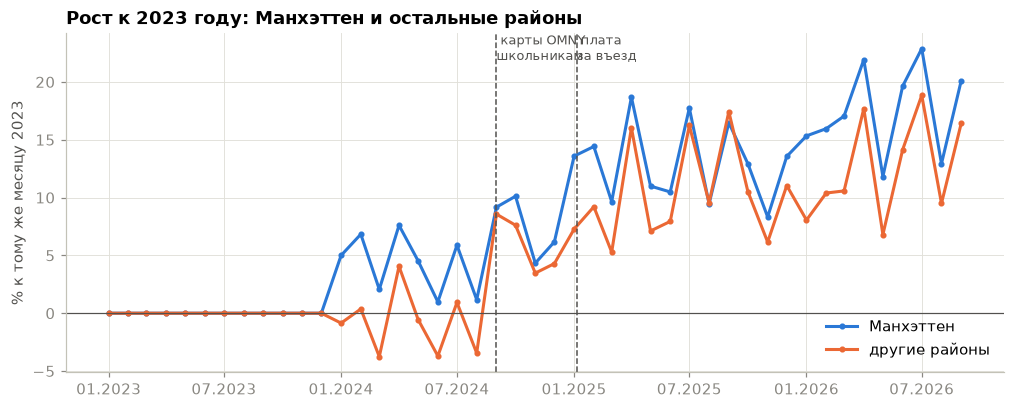

,"скачок, п.п. (сен–дек 2024 к май–авг 2024)"
будни 21–4 ч,7.7
будни 5–20 ч,5.0
выходные,10.5
Манхэттен,4.3
другие районы,7.7


In [2]:
op = df[(df["is_closed"] == 0) & (df["is_holiday"] == 0)].copy()
night = op["hour"].isin([21, 22, 23, 0, 1, 2, 3, 4])
op["группа"] = np.select(
    [(op["dow"] < 5) & ~night, (op["dow"] < 5) & night, op["dow"] >= 5],
    ["будни 5–20 ч", "будни 21–4 ч", "выходные"], "")
op["манхэттен"] = np.where(op["borough"] == "Manhattan", "Манхэттен", "другие районы")
op["ym"] = op["date"].dt.to_period("M")

def monthly_index(by):
    d = op.groupby(by + ["ym", "date"], observed=True)["ridership"].sum().reset_index()
    m = d.groupby(by + ["ym"], observed=True)["ridership"].mean().reset_index()
    m["month"] = m["ym"].dt.month
    m["year"] = m["ym"].dt.year
    b = m[m["year"] == 2023].set_index(by + ["month"])["ridership"]
    m["index"] = m["ridership"] / m.set_index(by + ["month"]).index.map(b)
    m["t"] = m["ym"].dt.to_timestamp()
    return m

def plot_index(m, by, title):
    fig, ax = plt.subplots()
    for i, (k, g) in enumerate(m.groupby(by)):
        ax.plot(g["t"], (g["index"] - 1) * 100, color=COL[i], marker="o", markersize=3, label=k)
    for d, lab in [("2024-09-01", "карты OMNY\nшкольникам"), ("2025-01-05", "плата\nза въезд")]:
        ax.axvline(pd.Timestamp(d), color=INK2, linestyle="--", linewidth=1)
        ax.text(pd.Timestamp(d), ax.get_ylim()[1], " " + lab, fontsize=8.5, color=INK2, va="top")
    ax.axhline(0, color=INK2, linewidth=0.8)
    ax.set_ylabel("% к тому же месяцу 2023"); ax.set_title(title); ax.legend(loc="lower right")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m.%Y")); plt.show()

m1 = monthly_index(["группа"])
plot_index(m1, "группа", "Рост к 2023 году: будни днём, будни ночью, выходные")
m2 = monthly_index(["манхэттен"])
plot_index(m2, "манхэттен", "Рост к 2023 году: Манхэттен и остальные районы")

def step(m, by):
    before = m[m["t"].between("2024-05-01", "2024-08-31")].groupby(by)["index"].mean()
    after = m[m["t"].between("2024-09-01", "2024-12-31")].groupby(by)["index"].mean()
    return ((after - before) * 100).round(1).rename("скачок, п.п. (сен–дек 2024 к май–авг 2024)")
display(pd.concat([step(m1, "группа"), step(m2, "манхэттен")]).to_frame())

## 2. Всплески и закрытия соседних станций

Соседи станции — станции **на той же линии** (линии берём из скобок в названии) не дальше 3 км.
Сравниваем, как часто сосед закрыт в день всплеска и в обычный день той же станции.
Если в дни всплесков соседи закрыты в разы чаще — это пересадка, а не событие.

In [3]:
import re

def lines_of(s):
    groups = re.findall(r"\(([^)]*)\)", s)
    return set(x.strip() for g in groups for x in g.split(",") if x.strip())

st["lines"] = st["station_complex"].map(lines_of)
lat, lon = np.radians(st["latitude"].values), np.radians(st["longitude"].values)
dlat = lat[:, None] - lat[None, :]
dlon = (lon[:, None] - lon[None, :]) * np.cos((lat[:, None] + lat[None, :]) / 2)
dist = 6371 * np.sqrt(dlat ** 2 + dlon ** 2)
ids = st["station_complex_id"].tolist()
neigh = {}
for i, a in enumerate(ids):
    la = st["lines"].iat[i]
    neigh[a] = [ids[j] for j in range(len(ids))
                if j != i and dist[i, j] <= 3 and la & st["lines"].iat[j]]
print(f"Среднее число соседей: {np.mean([len(v) for v in neigh.values()]):.1f}; "
      f"без соседей: {sum(len(v) == 0 for v in neigh.values())} станций")

closed = (df.groupby(["station_complex_id", "date"])["is_closed"].max()
            .reset_index().query("is_closed == 1"))
closed_set = set(zip(closed["station_complex_id"], closed["date"]))

days = df.loc[df["is_closed"] == 0, ["station_complex_id", "date"]].drop_duplicates()
days["сосед_закрыт"] = [any((n, d) in closed_set for n in neigh[s])
                        for s, d in zip(days["station_complex_id"], days["date"])]

spikes = pd.read_csv("../data/processed/event_spikes.csv", dtype={"station_complex_id": str},
                     parse_dates=["date"])
sp_days = spikes[["station_complex_id", "date"]].drop_duplicates().assign(всплеск=True)
days = days.merge(sp_days, on=["station_complex_id", "date"], how="left")
days["всплеск"] = days["всплеск"].fillna(False).astype(bool)

overall = days.groupby("всплеск")["сосед_закрыт"].mean()
print(f"Сосед закрыт: в день всплеска {overall[True]:.1%}, в обычный день {overall[False]:.1%} "
      f"(в {overall[True] / max(overall[False], 1e-9):.1f} раза чаще)")
print(f"Доля всех всплесков, совпавших с закрытием соседа: "
      f"{days.loc[days['всплеск'], 'сосед_закрыт'].mean():.0%}")

Среднее число соседей: 8.6; без соседей: 0 станций
Сосед закрыт: в день всплеска 7.1%, в обычный день 1.7% (в 4.1 раза чаще)
Доля всех всплесков, совпавших с закрытием соседа: 7%


In [4]:
ev = pd.read_csv("../data/processed/event_stations.csv", dtype={"station_complex_id": str})
top = ev[ev["в_год"] >= 10]["station_complex_id"]
rows = []
for s in top:
    d = days[days["station_complex_id"] == s]
    sp = d[d["всплеск"]]
    rows.append({"станция": name.get(s, s), "всплесков в год": round(ev.set_index("station_complex_id").loc[s, "в_год"], 1),
                 "соседей": len(neigh[s]),
                 "сосед закрыт в день всплеска": sp["сосед_закрыт"].mean(),
                 "сосед закрыт в обычный день": d.loc[~d["всплеск"], "сосед_закрыт"].mean()})
tab = pd.DataFrame(rows)
tab["тип"] = np.where(tab["сосед закрыт в день всплеска"] >= 0.5, "пересадка", "событие / другое")
show = tab.sort_values("сосед закрыт в день всплеска", ascending=False).copy()
for c in ["сосед закрыт в день всплеска", "сосед закрыт в обычный день"]:
    show[c] = show[c].map("{:.0%}".format)
display(show)
print(tab["тип"].value_counts().to_string())

,станция,всплесков в год,соседей,сосед закрыт в день всплеска,сосед закрыт в обычный день,тип
60,"168 St-Washington Hts (1,A,C)",11.3,14,96%,5%,пересадка
46,"Broadway Junction (A,C,J,Z,L)",13.4,25,93%,10%,пересадка
53,"Hewes St (M,J)",12.3,7,58%,4%,пересадка
55,"Bedford Park Blvd (B,D)",12.1,5,49%,1%,событие / другое
18,137 St-City College (1),23.6,7,34%,1%,событие / другое
27,238 St (1),19.0,5,32%,0%,событие / другое
66,"23 St (F,M)",10.2,11,21%,6%,событие / другое
7,"Coney Island-Stillwell Av (D,F,N,Q)",51.5,15,20%,10%,событие / другое
65,"Prospect Park (B,Q,S)",10.2,10,17%,5%,событие / другое
3,"W 8 St-NY Aquarium (F,Q)",61.9,8,15%,8%,событие / другое


тип
событие / другое    64
пересадка            3


In [5]:
# То же для «городских» дней: сколько из 381 дня-окна объясняются массовыми закрытиями
per_day = (days[days["всплеск"]].groupby("date")
             .agg(станций=("station_complex_id", "size"), доля_с_закрытым_соседом=("сосед_закрыт", "mean")))
big = per_day[per_day["станций"] >= 15].sort_values("станций", ascending=False)
big["тип"] = np.where(big["доля_с_закрытым_соседом"] >= 0.5, "массовые закрытия", "городское событие?")
print(big["тип"].value_counts().to_string())
display(big[big["тип"] == "городское событие?"].head(30)
           .assign(день=lambda t: t.index.dayofweek.map(lambda i: "Пн Вт Ср Чт Пт Сб Вс".split()[i]),
                   доля_с_закрытым_соседом=lambda t: t["доля_с_закрытым_соседом"].map("{:.0%}".format)))

тип
городское событие?    331


,станций,доля_с_закрытым_соседом,тип,день
date,,,,
2023-12-31,112,4%,городское событие?,Вс
2023-11-05,92,5%,городское событие?,Вс
2025-11-02,79,5%,городское событие?,Вс
2023-10-28,78,6%,городское событие?,Сб
2024-11-03,75,5%,городское событие?,Вс
2023-12-09,74,9%,городское событие?,Сб
2023-12-16,70,6%,городское событие?,Сб
2023-12-02,68,10%,городское событие?,Сб
2026-06-13,63,3%,городское событие?,Сб
